# Laporan Praktikum Statistika Probabilitas: Uji Validitas & Reliabilitas Instrumen
- **Nama Mahasiswa:** Emil Akbar
- **Dataset:** `Blank Quiz (Responses).xlsx` (Kelas 3 TI A — 29 Butir, 5 Dimensi)
- **Dosen Pengampu:** Mona Elviyenti, S.Si., M.Si.

In [1]:
# 1. Impor Pustaka yang Diperlukan
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [2]:
# 2. Unggah Berkas Excel Hasil Kuesioner
uploaded = files.upload()
file_excel = list(uploaded.keys())[0]
print(f"Berkas berhasil dimuat: {file_excel}")

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
Berkas berhasil dimuat: Blank Quiz (Responses).xlsx


In [3]:
# 3. Pemisahan Kolom Non-Likert (Demografi) dan Kolom Pernyataan
JUMLAH_KOLOM_DEMOGRAFI = 6

data_mentah = pd.read_excel(file_excel)
kolom_butir = data_mentah.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print(f"Total responden : {len(data_mentah)}")
print(f"Total butir     : {kolom_butir.shape[1]}")
print(f"Nilai kosong    : {int(kolom_butir.isna().sum().sum())}")

Total responden : 39
Total butir     : 29
Nilai kosong    : 0


In [4]:
# 4. Konversi Skala Likert Teks ke Skor Numerik (1-5)
pemetaan_skor = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

skor_num = kolom_butir.replace(pemetaan_skor).apply(pd.to_numeric, errors="coerce")
print(f"Sel gagal konversi: {int(skor_num.isna().sum().sum())}")
skor_num.head()

Sel gagal konversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya lebih sering menggunakan pemikiran atau jawaban yang dihasilkan AI daripada mengembangkan pemikiran sendiri.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa cemas ketika tidak dapat mengakses AI saat sedang mengerjakan tugas kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Penggunaan AI membuat saya lebih tertarik untuk mempelajari materi perkuliahan.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.],"Kebiasaan penggunaan teknologi digital [Saya sering mengerjakan tugas kuliah sambil melakukan aktivitas lain, seperti membuka media sosial atau menonton video]",Kebiasaan penggunaan teknologi digital [Saya sering memeriksa notifikasi smartphone meskipun sedang mengerjakan tugas kuliah.],Kebiasaan penggunaan teknologi digital [Saya sering menunda pengerjaan tugas karena lebih tertarik menggunakan gadget untuk kegiatan lain yang tidak berhubungan dengan tugas yang sedang saya kerjakan],"Kebiasaan penggunaan teknologi digital [Saya merasa menggunakan AI tidak membutuhkan tingkat konsentrasi yang tinggi, sehingga dapat dikerjakan bersamaan dengan kegiatan yang lain.]",Kebiasaan penggunaan teknologi digital [Saya tidak mengkhawatirkan hasil yang diberikan AI],Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjaka

In [5]:
# 5. Ekstraksi Nama Dimensi & Pengelompokan Butir
kelompok_dimensi = {}
for col in kolom_butir.columns:
    nama_dim = re.match(r"^(.*?) \[", col).group(1).strip()
    kelompok_dimensi.setdefault(nama_dim, []).append(col)

for nama_dim, items in kelompok_dimensi.items():
    print(f"- {nama_dim}: {len(items)} butir")

- Penggunaan AI pada tugas atau projek kuliah: 7 butir
- Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
- Kebiasaan penggunaan teknologi digital: 6 butir
- Prokrastinasi akademik.: 4 butir
- Rsspon emosional: 5 butir


In [6]:
# 6. Uji Validitas Butir (Korelasi Pearson & Corrected Item-Total Correlation)
n_resp = len(skor_num)
t_kritis = stats.t.ppf(0.975, n_resp - 2)
r_tabel = t_kritis / np.sqrt((n_resp - 2) + t_kritis**2)
print(f"n = {n_resp} | df = {n_resp - 2} | t-kritis = {t_kritis:.3f} | r-tabel = {r_tabel:.3f}")

daftar_validitas = []
for idx_d, (nama_dim, items) in enumerate(kelompok_dimensi.items(), 1):
    matriks_dim = skor_num[items]
    skor_total_dim = matriks_dim.sum(axis=1)
    for idx_b, col in enumerate(items, 1):
        r_val, p_val = stats.pearsonr(matriks_dim[col], skor_total_dim)
        r_corr, _ = stats.pearsonr(matriks_dim[col], skor_total_dim - matriks_dim[col])
        daftar_validitas.append({
            "Dimensi": nama_dim,
            "Kode": f"D{idx_d}.B{idx_b}",
            "r hitung": round(r_val, 3),
            "Corrected r": round(r_corr, 3),
            "p-value": round(p_val, 4),
            "Status": "Valid" if r_val > r_tabel else "Tidak valid",
        })

df_validitas = pd.DataFrame(daftar_validitas)
df_validitas

n = 39 | df = 37 | t-kritis = 2.026 | r-tabel = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.525,0.277,0.0006,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.643,0.379,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.669,0.397,0.0000,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.515,0.126,0.0008,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.455,0.139,0.0036,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,0.538,0.228,0.0004,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,0.645,0.377,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,0.495,0.213,0.0014,Valid


In [7]:
# 7. Uji Reliabilitas (Cronbach's Alpha & Alpha if Item Deleted)
def hitung_cronbach_alpha(matriks):
    k = matriks.shape[1]
    var_butir = matriks.var(ddof=1).sum()
    var_total = matriks.sum(axis=1).var(ddof=1)
    return (k / (k - 1)) * (1 - var_butir / var_total)

def label_reliabilitas(alpha):
    if alpha >= 0.90:
        return "Sangat baik"
    elif alpha >= 0.80:
        return "Baik"
    elif alpha >= 0.70:
        return "Reliabel"
    return "Tidak reliabel"

daftar_reliabilitas = []
daftar_alpha_hapus = []
for idx_d, (nama_dim, items) in enumerate(kelompok_dimensi.items(), 1):
    matriks_dim = skor_num[items]
    alpha_dim = hitung_cronbach_alpha(matriks_dim)
    daftar_reliabilitas.append({
        "Dimensi": nama_dim,
        "Jumlah Butir": len(items),
        "Cronbach's Alpha": round(alpha_dim, 3),
        "Kategori": label_reliabilitas(alpha_dim),
    })
    if len(items) > 2:
        for idx_b, col in enumerate(items, 1):
            alpha_tanpa = hitung_cronbach_alpha(matriks_dim.drop(columns=col))
            daftar_alpha_hapus.append({
                "Dimensi": nama_dim,
                "Kode": f"D{idx_d}.B{idx_b}",
                "Alpha jika dihapus": round(alpha_tanpa, 3),
            })

df_reliabilitas = pd.DataFrame(daftar_reliabilitas)
df_alpha_hapus = pd.DataFrame(daftar_alpha_hapus)
display(df_reliabilitas)
display(df_alpha_hapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,7,0.375,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.478,Tidak reliabel
3,Prokrastinasi akademik.,4,0.863,Baik
4,Rsspon emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B1,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B2,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,B3,0.312


,Dimensi / Butir,Mean,Median,Std Dev (SD),Skewness,Kurtosis
0,[TOTAL DIMENSI] Penggunaan AI pada tugas atau projek kuliah,27.282,27.0,3.017,-0.425,1.612
1,Penggunaan AI pada tugas atau projek kuliah - B1,4.026,4.0,0.843,-0.606,-0.057
2,Penggunaan AI pada tugas atau projek kuliah - B2,4.487,4.0,0.506,0.053,-2.108
3,Penggunaan AI pada tugas atau projek kuliah - B3,4.256,4.0,0.993,-1.743,2.975
4,Penggunaan AI pada tugas atau projek kuliah - B4,2.949,3.0,1.050,-0.037,-0.691
5,Penggunaan AI pada tugas atau projek kuliah - B5,2.974,3.0,1.224,-0.130,-1.170
6,Penggunaan AI pada tugas atau projek kuliah - B6,4.179,4.0,0.997,-1.388,1.847
7,Penggunaan AI pada tugas atau projek kuliah - B7,4.410,5.0,0.818,-1.519,2.143
8,[TOTAL DIMENSI] Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,21.923,21.0,3.737,0.248,-0.752
9,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah - B1,3.487,4.0,1.275,-0.291,-1.160


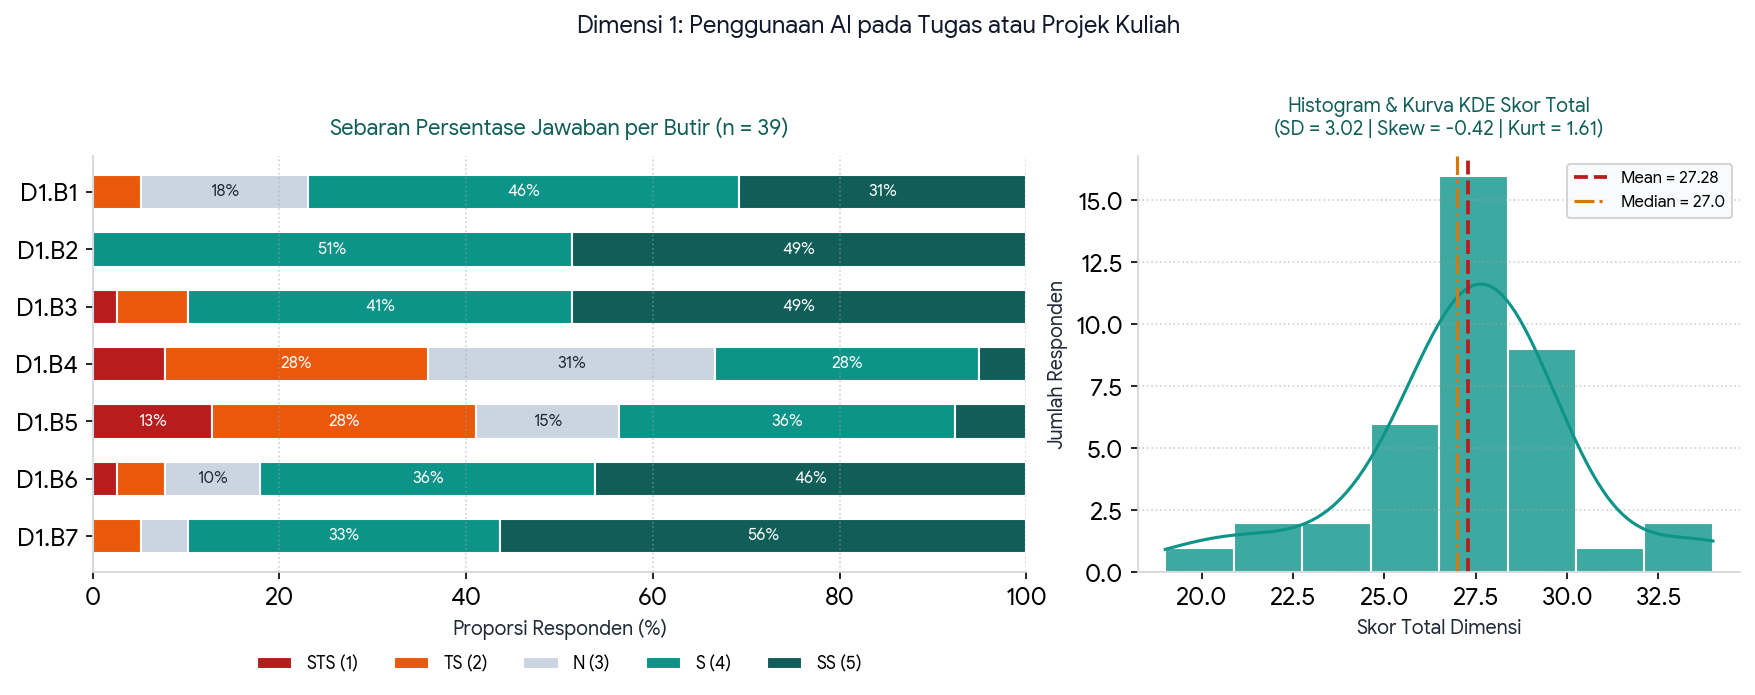

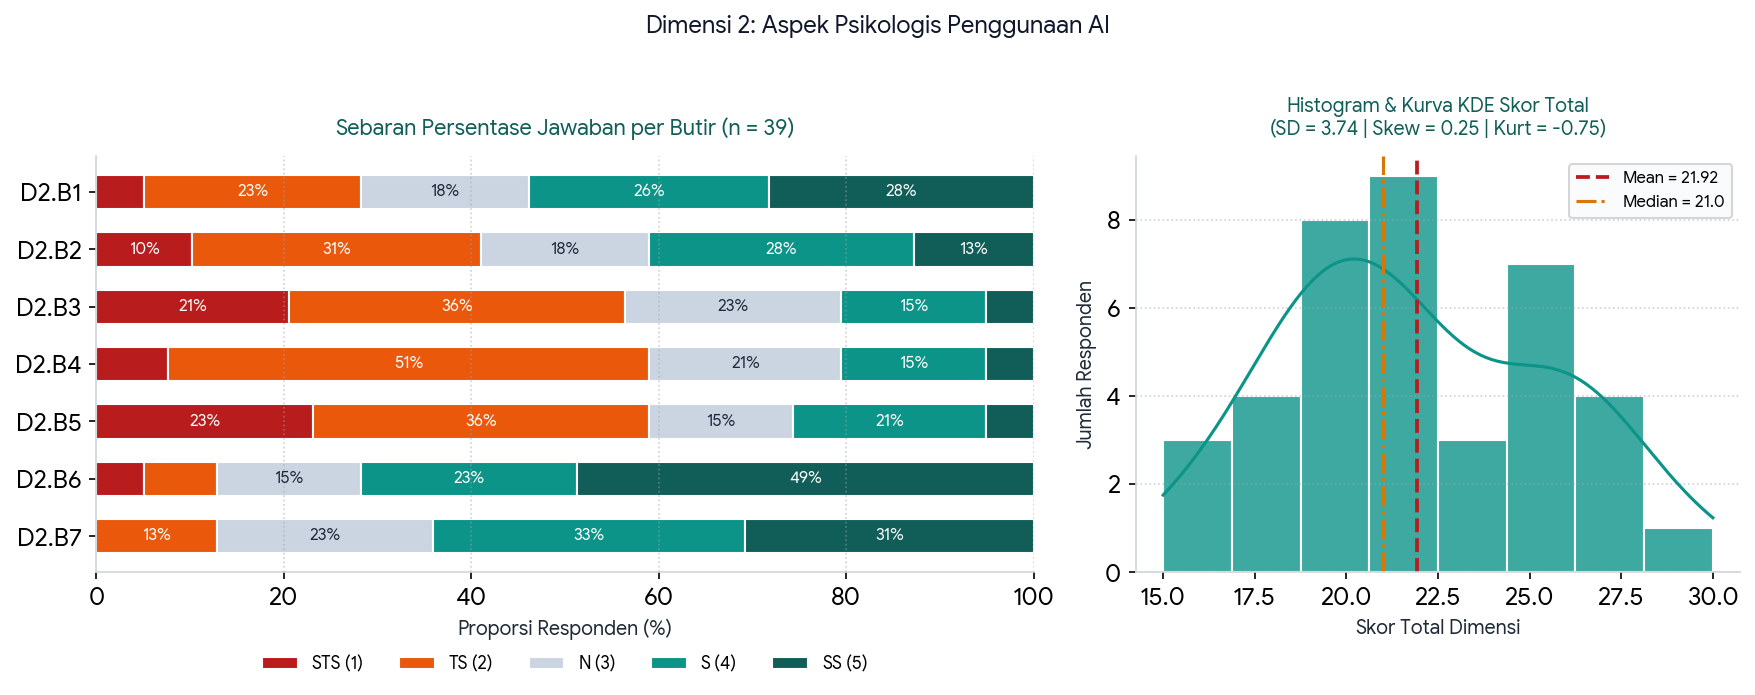

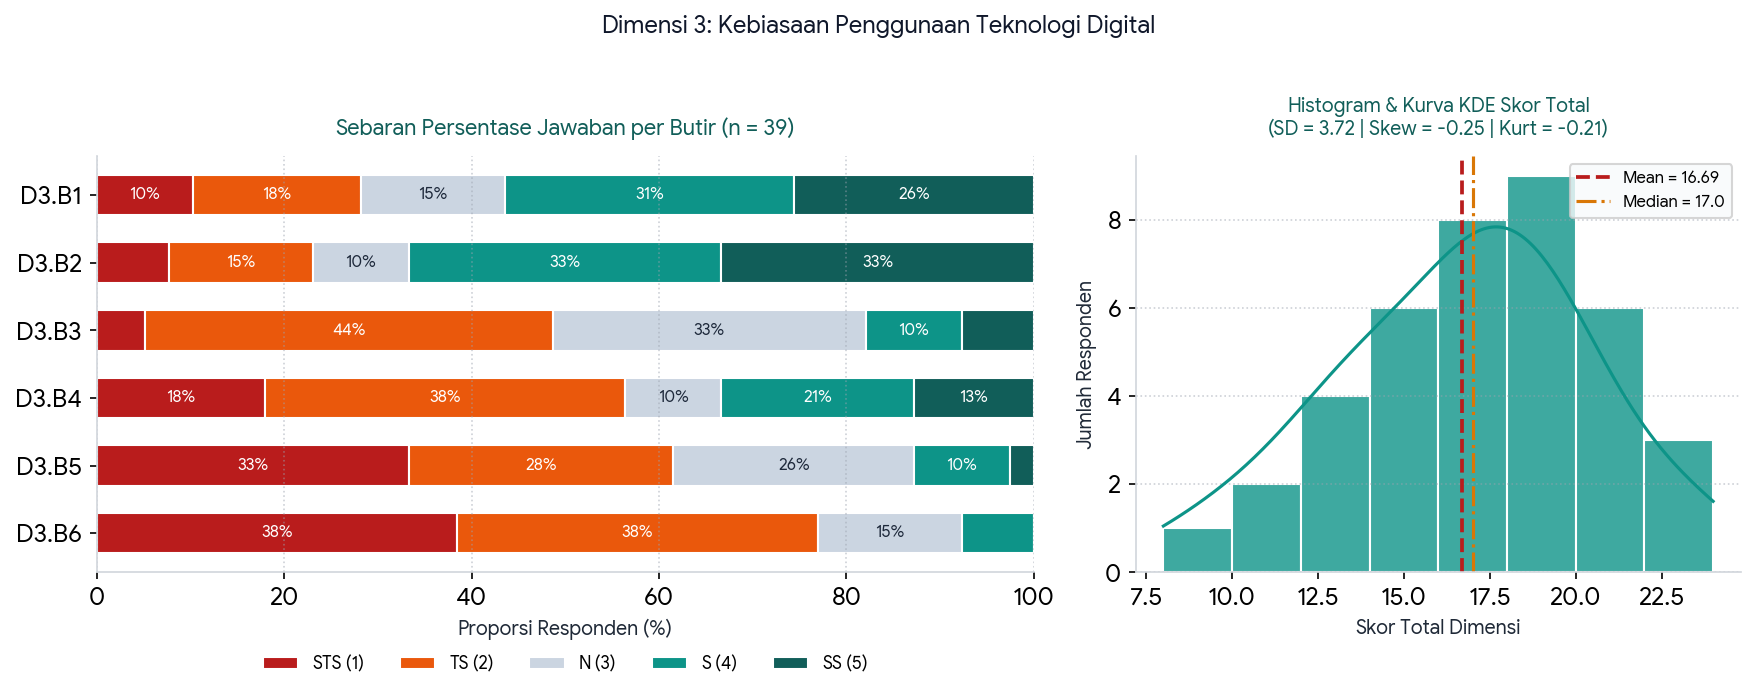

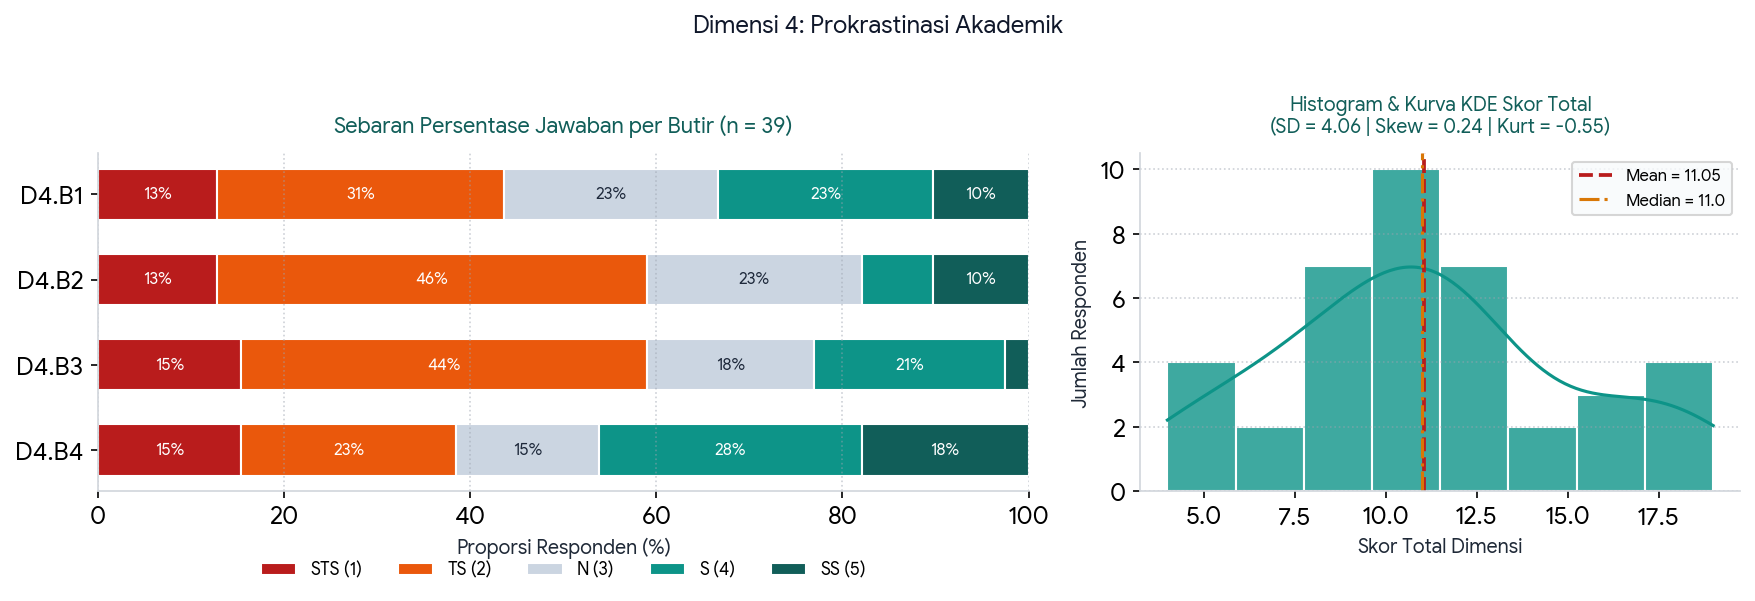

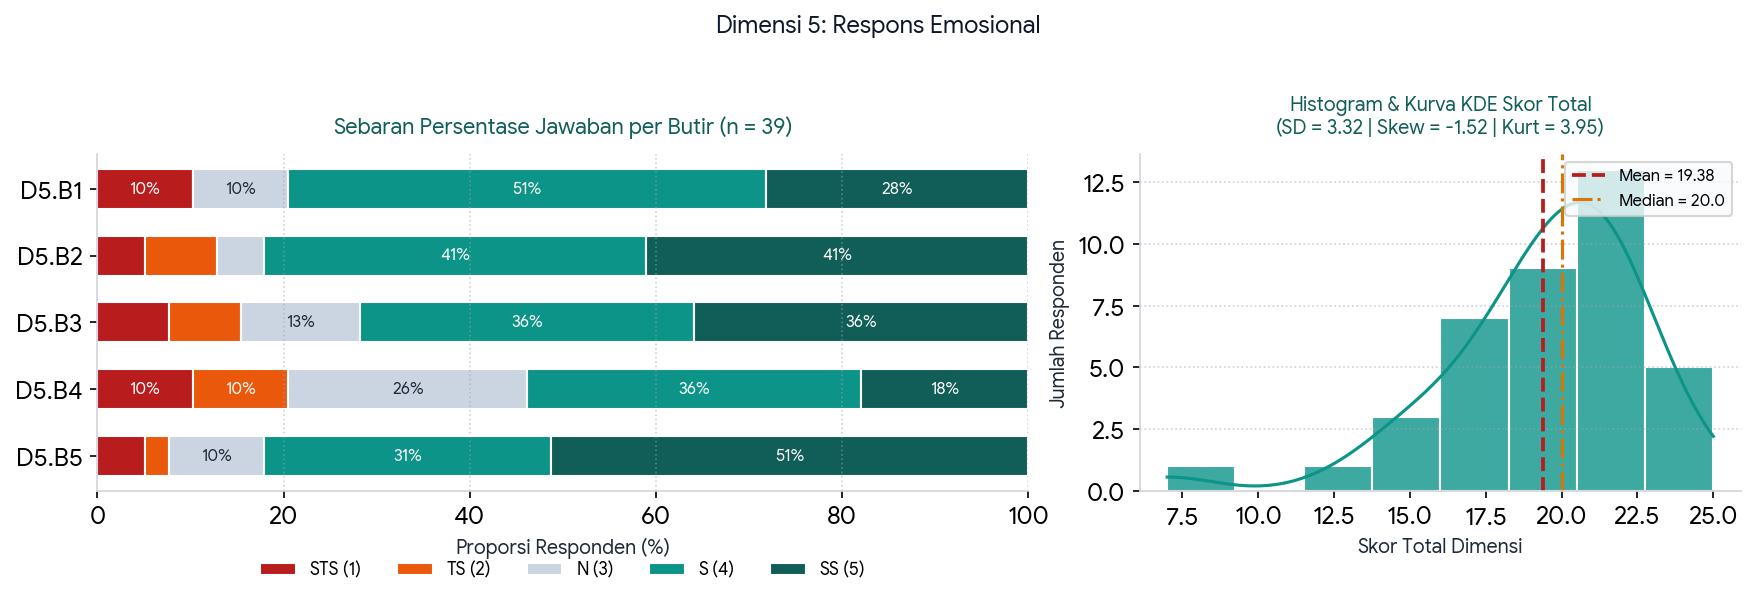

In [8]:
# 8. Analisis Statistik Deskriptif & Visualisasi Komposisi Jawaban
baris_deskriptif = []
for nama_dim, items in kelompok_dimensi.items():
    matriks_dim = skor_num[items]
    total_dim = matriks_dim.sum(axis=1)
    baris_deskriptif.append({
        "Dimensi / Butir": f"[TOTAL] {nama_dim}",
        "Mean": round(total_dim.mean(), 3),
        "Median": round(total_dim.median(), 3),
        "Std Dev": round(total_dim.std(ddof=1), 3),
        "Skewness": round(total_dim.skew(), 3),
        "Kurtosis": round(total_dim.kurt(), 3),
    })
    for i, col in enumerate(items, 1):
        s = matriks_dim[col]
        baris_deskriptif.append({
            "Dimensi / Butir": f"  {nama_dim} - B{i}",
            "Mean": round(s.mean(), 3),
            "Median": round(s.median(), 3),
            "Std Dev": round(s.std(ddof=1), 3),
            "Skewness": round(s.skew(), 3),
            "Kurtosis": round(s.kurt(), 3),
        })

df_deskriptif = pd.DataFrame(baris_deskriptif)
display(df_deskriptif)

skala_labels = ['STS (1)', 'TS (2)', 'N (3)', 'S (4)', 'SS (5)']
palet_warna = ['#B91C1C', '#EA580C', '#CBD5E1', '#0D9488', '#115E59']

for idx_d, (nama_dim, items) in enumerate(kelompok_dimensi.items(), 1):
    matriks_dim = skor_num[items]
    kode_butir = [f'D{idx_d}.B{i}' for i in range(1, len(items)+1)]
    frek = pd.DataFrame(index=kode_butir, columns=[1, 2, 3, 4, 5])
    for i, col in enumerate(items):
        frek.loc[kode_butir[i]] = matriks_dim[col].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0).values
    persen = frek.div(frek.sum(axis=1), axis=0) * 100

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1.55, 1]})
    kiri = np.zeros(len(kode_butir))
    for val, lbl, warna in zip([1, 2, 3, 4, 5], skala_labels, palet_warna):
        w = persen[val].values.astype(float)
        ax1.barh(kode_butir, w, left=kiri, label=lbl, color=warna, edgecolor='white', height=0.6)
        kiri += w
    ax1.set_xlim(0, 100)
    ax1.invert_yaxis()
    ax1.set_xlabel('Proporsi Responden (%)')
    ax1.set_title(f'Sebaran Jawaban Dimensi {idx_d}: {nama_dim}')
    ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=False)

    total_dim = matriks_dim.sum(axis=1)
    sns.histplot(total_dim, kde=True, ax=ax2, color='#0D9488', bins=8)
    ax2.axvline(total_dim.mean(), color='#B91C1C', linestyle='--', label=f'Mean = {total_dim.mean():.2f}')
    ax2.set_title(f'Distribusi Skor Total (SD={total_dim.std(ddof=1):.2f}, Skew={total_dim.skew():.2f}, Kurt={total_dim.kurt():.2f})')
    ax2.legend()
    plt.tight_layout()
    plt.show()

In [9]:
# 9. Simulasi Perbaikan Reliabilitas & Ekspor Hasil ke Excel
rekap_gabung = df_validitas.merge(df_alpha_hapus, on=["Dimensi", "Kode"], how="left")
nama_output_excel = "hasil_uji_validitas_reliabilitas_EmilAkbar.xlsx"
with pd.ExcelWriter(nama_output_excel) as writer:
    rekap_gabung.to_excel(writer, sheet_name="Validitas", index=False)
    df_reliabilitas.to_excel(writer, sheet_name="Reliabilitas", index=False)
    df_deskriptif.to_excel(writer, sheet_name="Deskriptif", index=False)

files.download(nama_output_excel)